# 10. 전망 모델 합치기 — 선발을 모를 때는 어떤 모델이 맞을까?

안녕하세요! **KBO 승패 예측 프로젝트의 열 번째 이야기**예요. 짝이 되는 코드는 `src/kbo_predict/outlook_eval.py`예요.

**이 노트북이 하는 일**
- 사이트의 시리즈 전망·가을야구 확률은 **아직 선발을 모르는 미래 경기**의 확률로 계산해요. 그때 쓸 모델 다섯 개를 비교해요.
- 정규시즌 경기는 실제 선발을 **가린 채로**, 가을야구 경기는 정규시즌 끝 상태로 채점해요. 가을야구 시리즈 37개의 승자도 맞혀 봐요.
- 미리 정한 규칙으로 하나를 고르고, 2026 한국시리즈 날마다 시리즈 전망이 어떻게 달라졌을지 다시 계산해요.

**왜 하나요?**
- 지금까지 사이트는 확률을 **두 모델**로 냈어요. 경기 예측은 승패 모델 v0.3(선발 + Elo), 전망은 선발 없는 팀 모델(팀 기록만)이었어요.
- 2026 한국시리즈 전에 두 모델이 **다른 팀**을 골랐어요(경기 예측 KT, 시리즈 전망 삼성). 한 화면에서 숫자가 엇갈리면 읽는 사람이 헷갈려요(09번).
- 그래서 "하나로 합쳐도 되나, 합친다면 무엇으로"를 숫자로 정하려는 거예요.

## 1. 준비

09번과 같은 준비예요. `KBO_DATA_DIR`로 데이터 폴더를 알려 주고, 결과 파일 `data/public/outlook_model_report.json`(명령줄 `python -m kbo_predict.outlook_eval`이 만든 것)을 읽어요.

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # scikit-learn이 코어 수를 찾다 내는 경고를 막아요
warnings.filterwarnings("ignore")                          # 라이브러리 버전·수렴 안내 메시지는 숨겨요 (계산에는 영향 없음)

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
os.environ["KBO_DATA_DIR"] = str(ROOT / "data")            # raw_store가 경기·박스스코어 파일을 찾는 폴더

from kbo_predict import outlook_eval as oe                  # 전망 모델 합치기 (이 노트북의 짝)
from kbo_predict.features import load_features

plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

df = load_features(ROOT / "data" / "processed" / "features.parquet")
report = json.loads((ROOT / "data" / "public" / "outlook_model_report.json").read_text(encoding="utf-8"))
KO = report["candidates"]                                   # 후보 다섯 개의 한글 이름
TEAM_KO = {"OB": "두산", "LT": "롯데", "KT": "KT", "WO": "키움", "SK": "SSG", "SS": "삼성", "HH": "한화", "HT": "KIA", "LG": "LG", "NC": "NC"}
print(f"결과 파일 만든 시각 {report['generated_at']} · 계산에 걸린 시간 {report['elapsed_sec']}초")

결과 파일 만든 시각 2026-11-09T17:53:52+09:00 · 계산에 걸린 시간 7.1초


## 2. 후보 다섯 개와 고르는 규칙 — 계산 전에 정했어요

| 후보 | 무엇 |
|---|---|
| `team` | 예전 전망 모델: 팀 기록 19개, L2 (Elo·선발 없음) |
| `team_elo` | 팀 기록 + Elo, L2 |
| `team_l1_elo` | 팀 기록 + Elo, L1 C = 0.03 (v0.3 설정에서 선발 피처만 빼고 따로 학습) |
| `win_masked` | **v0.3 그 자체**에 선발을 '모름'으로 넣기 → 경기 예측과 전망이 **한 모델** |
| `avg` | `win_masked`와 `team`의 평균 |

**'선발 모름'으로 넣는다는 건?** 선발 피처 7개 중 `starter_known`을 0으로, 나머지 6개는 비워 둬요. 모델은 빈 값을 학습 때의 중앙값으로 채워요. 라이브에서 선발이 아직 발표되지 않은 경기와 **똑같은 입력**이에요(`tests/test_outlook_eval.py`가 확인해요).

**고르는 규칙** (2026-11-09, 계산 전):
1. 2018~2025(정규시즌 + 가을야구) log loss가 가장 낮은 후보 = best.
2. `win_masked`가 best이거나, best보다 나빠도 그 차이가 **p ≥ 0.05**(우연과 구분 안 됨)이면 `win_masked`를 골라요. 성적이 같다면 모델이 하나인 쪽이 읽기 쉽고 관리하기 쉬워서예요.
3. 아니면 best를 골라요. 2026은 고른 뒤 채점만 해요.

In [2]:
print("규칙:", report["protocol"]["rule"])
print("정한 때:", report["protocol"]["rule_declared"])
display(pd.DataFrame({"후보": list(KO), "이름": list(KO.values())}).set_index("후보"))

규칙: 개발 시즌 log loss 최저(best). win_masked가 best이거나 best와의 차이가 p ≥ 0.05면 win_masked(한 모델), 아니면 best
정한 때: 2026-11-09 (계산 전)


,이름
후보,
team,"예전 전망 모델 (팀 기록만, L2)"
team_elo,팀 기록 + Elo (L2)
team_l1_elo,"팀 기록 + Elo (L1, v0.3에서 선발만 뺌)"
win_masked,v0.3 하나로 합치기 (선발 모름으로 넣음)
avg,v0.3(선발 모름)과 팀 모델의 평균


## 3. 다시 계산해서 결과 파일과 같은지 확인

`oe.run(df)`가 명령줄과 똑같은 계산을 해요. 아홉 시즌마다 모델 네 개를 새로 학습하고, 정규시즌·가을야구 경기와 시리즈, 2026 한국시리즈 전망까지 다시 내요.

In [3]:
rerun = json.loads(json.dumps(oe.run(df, log=lambda *_: None), ensure_ascii=False))
for key in ("pooled", "by_season", "tests_dev", "best_dev", "chosen", "series_summary", "ks_2026"):
    print(f"{key:15s} 결과 파일과 같나요? {rerun[key] == report[key]}")

pooled          결과 파일과 같나요? True
by_season       결과 파일과 같나요? True
tests_dev       결과 파일과 같나요? True
best_dev        결과 파일과 같나요? True
chosen          결과 파일과 같나요? True
series_summary  결과 파일과 같나요? True
ks_2026         결과 파일과 같나요? True


**해석:** 모두 `True`면 사이트 성적표의 "전망 모델 하나로 합치기" 숫자는 이 노트북의 계산과 같아요.

## 4. 경기 단위 성적 — 선발을 모를 때

**출력 보는 법:**
- 적중률·log loss는 선발을 가린 확률로 채점한 거예요. 그래서 선발을 아는 경기 예측(57~58%)보다 낮아요.
- `경기 예측과 엇갈림`은 선발을 아는 v0.3과 다른 팀을 고른 경기의 비율이에요. 한 화면 안에서 숫자가 얼마나 엇갈릴 수 있는지 보여 줘요.

In [4]:
P = report["pooled"]
rows = []
for n in KO:
    rows.append({"후보": KO[n], "2018~2025 적중률": P["dev"][n]["accuracy"], "2018~2025 log loss": P["dev"][n]["log_loss"],
                 "그중 가을야구 log loss": P["dev_postseason"][n]["log_loss"], "2026 적중률": P["test"][n]["accuracy"],
                 "2026 log loss": P["test"][n]["log_loss"], "경기 예측과 엇갈림": P["dev"][n]["disagree_with_game_model"]})
tbl = pd.DataFrame(rows).set_index("후보")
display(tbl.style.format({c: "{:.1%}" for c in ("2018~2025 적중률", "2026 적중률", "경기 예측과 엇갈림")} | {
    c: "{:.4f}" for c in ("2018~2025 log loss", "그중 가을야구 log loss", "2026 log loss")}))
print(f"경기 수: 2018~2025 {P['dev']['n']:,} (그중 가을야구 {P['dev_postseason']['n']}), 2026 {P['test']['n']}")
for n, t in report["tests_dev"].items():
    print(f"[2018~2025] {KO[n]} vs 예전 전망 모델: log loss {t['logloss_gain']:+.4f} 좋아짐, p = {t['logloss_p']:.4f}")
print(f"best = {report['best_dev']} / 합친 모델 vs best: p = {report['unified_vs_best']['logloss_p']:.3f} → 고른 것: {report['chosen']}")

,2018~2025 적중률,2018~2025 log loss,그중 가을야구 log loss,2026 적중률,2026 log loss,경기 예측과 엇갈림
후보,,,,,,
"예전 전망 모델 (팀 기록만, L2)",54.0%,0.6903,0.6842,55.0%,0.6868,23.7%
팀 기록 + Elo (L2),54.4%,0.6886,0.6845,55.7%,0.6838,22.6%
"팀 기록 + Elo (L1, v0.3에서 선발만 뺌)",55.6%,0.6848,0.6829,56.7%,0.6818,19.4%
v0.3 하나로 합치기 (선발 모름으로 넣음),54.9%,0.6858,0.6857,55.6%,0.6838,23.1%
v0.3(선발 모름)과 팀 모델의 평균,54.4%,0.6867,0.6837,55.2%,0.6849,22.1%


경기 수: 2018~2025 5,741 (그중 가을야구 115), 2026 716
[2018~2025] 팀 기록 + Elo (L2) vs 예전 전망 모델: log loss +0.0017 좋아짐, p = 0.0266
[2018~2025] 팀 기록 + Elo (L1, v0.3에서 선발만 뺌) vs 예전 전망 모델: log loss +0.0055 좋아짐, p = 0.0000
[2018~2025] v0.3 하나로 합치기 (선발 모름으로 넣음) vs 예전 전망 모델: log loss +0.0044 좋아짐, p = 0.0011
[2018~2025] v0.3(선발 모름)과 팀 모델의 평균 vs 예전 전망 모델: log loss +0.0036 좋아짐, p = 0.0000
best = team_l1_elo / 합친 모델 vs best: p = 0.097 → 고른 것: win_masked


**해석:**
- **예전 전망 모델(팀 기록만)이 다섯 후보 중 가장 나빠요**(log loss 0.6903). Elo를 넣은 후보들이 모두 더 좋아요. 여러 시즌 쌓은 전력 점수가 "선발 모를 때"에도 큰 정보라는 뜻이에요.
- 가장 좋은 건 `team_l1_elo`(0.6848)이고, v0.3을 그대로 쓰는 `win_masked`(0.6858)는 0.001 뒤져요. 이 차이는 p = 0.097로 **우연과 구분되지 않아요**.
- 그래서 규칙 2번에 따라 **`win_masked` — 한 모델로 합치기**를 골랐어요. 예전 전망 모델보다는 확실히 좋아요(log loss 0.0044 좋아짐, p = 0.001).
- 2026에서도 순서는 비슷해요(예전 모델이 가장 나쁨).
- 엇갈림 비율이 합친 뒤에도 0이 아닌 건 **선발 정보** 때문이에요. 같은 모델이라도 선발을 알면 확률이 달라져요. 이제 사이트에서 엇갈림이 생기면 그 이유는 "선발 발표 여부" 하나뿐이에요.

## 5. 시즌별로 보기

**출력 보는 법:** 파란 굵은 선 = 합친 모델(`win_masked`), 회색 선 = 예전 전망 모델(`team`), 주황 점선 = `team_l1_elo`. 낮을수록 좋은 log loss예요.

,v0.3 하나로 합치기 (선발 모름으로 넣음),"예전 전망 모델 (팀 기록만, L2)","팀 기록 + Elo (L1, v0.3에서 선발만 뺌)"
2018,0.6885,0.6990,0.6881
2019,0.6786,0.6877,0.6781
2020,0.6844,0.6804,0.6800
2021,0.6888,0.6913,0.6880
2022,0.6841,0.6880,0.6810
2023,0.6863,0.6916,0.6867
2024,0.6888,0.6927,0.6890
2025,0.6876,0.6916,0.6874
2026,0.6838,0.6868,0.6818


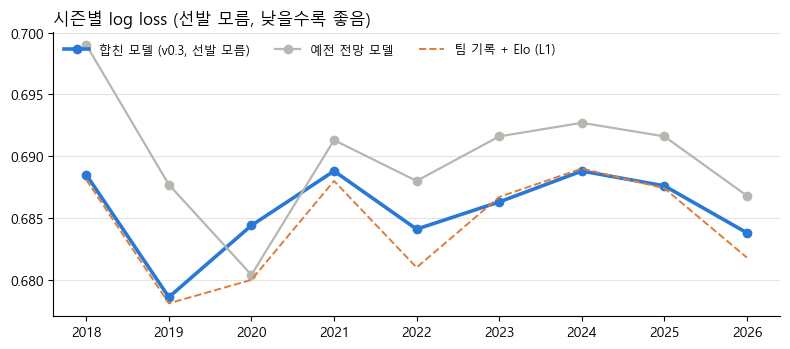

합친 모델이 예전 모델보다 좋은 시즌: 8 / 9


In [5]:
seasons = report["seasons"]
per = pd.DataFrame({KO[n]: [report["by_season"][str(s)][n]["log_loss"] for s in seasons] for n in ("win_masked", "team", "team_l1_elo")}, index=seasons)
display(per.style.format("{:.4f}"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(seasons, per[KO["win_masked"]], color=BLUE, lw=2.6, marker="o", label="합친 모델 (v0.3, 선발 모름)")
ax.plot(seasons, per[KO["team"]], color=GRAY, lw=1.6, marker="o", label="예전 전망 모델")
ax.plot(seasons, per[KO["team_l1_elo"]], color=ORANGE, lw=1.4, ls="--", label="팀 기록 + Elo (L1)")
ax.set_title("시즌별 log loss (선발 모름, 낮을수록 좋음)", loc="left"); ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()
print("합친 모델이 예전 모델보다 좋은 시즌:", sum(per[KO['win_masked']] < per[KO['team']]), "/", len(seasons))

**해석:** 합친 모델은 아홉 시즌 대부분에서 예전 전망 모델보다 낮아요(좋아요). `team_l1_elo`와는 시즌마다 엎치락뒤치락해서 둘의 차이는 작아요. 한두 시즌이 끌어올린 결과가 아니라 꾸준한 차이예요.

## 6. 시리즈 단위 — 시작 전 우세 팀

09번과 같은 방법(선발 모름, 두 구장 평균)으로 가을야구 시리즈 37개의 승자를 시작 전에 맞혔는지 봐요.

In [6]:
S = report["series_summary"]
display(pd.DataFrame([{"범위": lab, "시리즈": S[k]["n"], **{KO[n]: S[k][n] for n in KO}} for lab, k in
                      (("2018~2025", "dev"), ("2026", "test"), ("전체", "all"))]).set_index("범위"))

,시리즈,"예전 전망 모델 (팀 기록만, L2)",팀 기록 + Elo (L2),"팀 기록 + Elo (L1, v0.3에서 선발만 뺌)",v0.3 하나로 합치기 (선발 모름으로 넣음),v0.3(선발 모름)과 팀 모델의 평균
범위,,,,,,
2018~2025,33,21,19,20,22,20
2026,4,3,2,3,3,2
전체,37,24,21,23,25,22


**해석:** 37개 중 합친 모델이 **25개**로 가장 많이 맞혔고, 예전 전망 모델은 24개였어요. 다만 시리즈는 수가 적고 대부분 반반에 가까워서, 이 차이만으로 결론을 내지는 않아요. 경기 단위 log loss가 주된 근거예요.

## 7. 2026 한국시리즈 — 합쳤다면 전망이 어떻게 나왔을까?

날마다 사이트의 시리즈 전망(남은 경기 1만 번 가상 시뮬레이션)을 두 모델로 다시 계산해요. 오늘 경기는 둘 다 예고 선발을 아는 승패 모델 확률이고, 남은 경기만 모델이 달라요.
모델은 2015~2025로 학습한 것이라 그때 사이트 숫자(삼성 51.4%)와 조금 달라요.

,전적 (KT-삼성),합친 모델: KT 우승,예전 모델: KT 우승
날짜,,,
2026-11-03,0-0,56.0%,49.9%
2026-11-04,1-0,69.6%,64.8%
2026-11-06,1-1,53.0%,48.1%
2026-11-07,1-2,36.6%,33.2%
2026-11-08,1-3,15.3%,13.6%


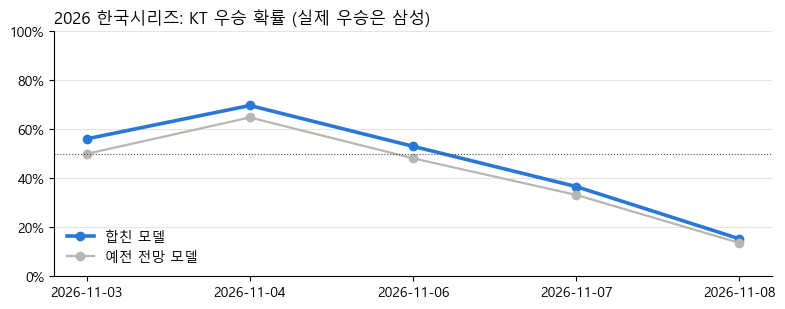

In [7]:
ks = pd.DataFrame([{"날짜": k["date"], "전적 (KT-삼성)": f"{k['wins'][0]}-{k['wins'][1]}",
                     "합친 모델: KT 우승": k["unified"][0], "예전 모델: KT 우승": k["old_team"][0]} for k in report["ks_2026"]]).set_index("날짜")
display(ks.style.format({c: "{:.1%}" for c in ks.columns if "우승" in c}))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ks.index, ks["합친 모델: KT 우승"], color=BLUE, lw=2.6, marker="o", label="합친 모델")
ax.plot(ks.index, ks["예전 모델: KT 우승"], color=GRAY, lw=1.6, marker="o", label="예전 전망 모델")
ax.axhline(0.5, color=INK, lw=0.8, ls=":"); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, 1)
ax.set_title("2026 한국시리즈: KT 우승 확률 (실제 우승은 삼성)", loc="left"); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**해석:**
- 합친 모델이었다면 1차전 전 전망은 **KT 우승 56%**였을 거예요. 예전 모델은 반반(50%)이었고, 실제로는 삼성이 우승했어요. **이번 한 시리즈에서는 예전 모델 쪽이 결과에 가까웠어요.**
- 그래도 모델은 한 시리즈가 아니라 여러 시즌 성적으로 골라요. 한 시리즈의 결과는 운에 크게 흔들리고(09번: 시작 전 확률이 대부분 50~56%), 9시즌 경기 단위로는 합친 모델이 확실히 나았어요.
- 날이 갈수록 두 선의 차이는 줄어요. 남은 경기가 적어지면 이미 치른 결과가 확률을 대부분 정하기 때문이에요.

## 8. 정직하게 적어 둘 점과 결론

**정직하게 적어 둘 점**
1. 이 시험은 2026 한국시리즈에서 두 모델이 엇갈린 것을 본 뒤에 시작했어요. 다만 후보와 고르는 규칙은 계산 전에 정했어요.
2. `win_masked`는 가장 좋은 후보(`team_l1_elo`)보다 log loss가 0.001 높아요. 우연과 구분되지 않는 차이라서 "한 모델"이라는 장점을 택했어요.
3. 합친 모델이었다면 2026 한국시리즈 전망은 틀린 쪽(KT)을 더 높게 봤을 거예요. 그 사실도 성적표에 적었어요.

**결론**
- 2026-11-09부터 시리즈 전망·가을야구 확률도 **경기 예측과 같은 v0.3**으로 계산해요(남은 경기는 선발 '모름'). 라이브(`run_pipeline`)와 되감기(`report-2026`) 모두요.
- 이제 같은 경기를 두 모델이 다르게 보는 일이 없어요. 오늘 경기와 남은 경기의 차이는 선발 발표 여부뿐이에요.
- 예전 팀 모델 `team-2026`은 성적표의 "선발 없이" 비교용으로만 남겨 둬요.

In [8]:
print(f"노트북 전체 실행 시간: {time.time() - T0:.0f}초")

노트북 전체 실행 시간: 10초
